# EN3150 Assignment 03: Custom Model Training & Evaluation

This notebook covers:
1. **Training**: Trains both **Model A (Standard CNN, 617,284 params)** and **Model B (Lightweight Depthwise Separable CNN, 19,885 params)** for **20 epochs** on the OCTMNIST dataset using our selected **Adam (`lr=0.001`)** optimizer.
2. **Learning Curves**: Plots and compares training and validation loss and accuracy curves across all 20 epochs.
3. **Test Set Evaluation**: Evaluates both models on the deduplicated test set (`15,172` images), reporting **Test Accuracy, Precision, Recall, F1-Score, and Confusion Matrices**.
4. **Model Comparison & Trade-off Analysis**: Compares Model A and Model B across Total Parameter Count, Estimated Model Size on Disk (KB), Training Time per Epoch (s), and Test Accuracy, followed by an in-depth hardware and representational trade-off discussion.

In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import load_octmnist_datasets, SEED, DEFAULT_BATCH_SIZE, NUM_CLASSES
from src.models import build_model_a, build_model_b

tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs    : {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.21.0
Available GPUs    : []


In [2]:
# Load OCTMNIST datasets and evaluation arrays
(train_ds, val_ds, test_ds), (X_train, y_train, X_val_eval, y_val_eval, X_test_eval, y_test_eval), info = (
    load_octmnist_datasets(batch_size=DEFAULT_BATCH_SIZE)
)

class_names = [info["label"][str(i)] for i in range(NUM_CLASSES)]
short_class_names = ["CNV", "DME", "Drusen", "Normal"]

print(f"Training samples   : {len(X_train):,}")
print(f"Validation samples : {len(X_val_eval):,}")
print(f"Testing samples    : {len(X_test_eval):,}")
print(f"Class mapping      : {dict(zip(short_class_names, class_names))}")

Training samples   : 76,128
Validation samples : 15,170
Testing samples    : 15,172
Class mapping      : {'CNV': 'choroidal neovascularization', 'DME': 'diabetic macular edema', 'Drusen': 'drusen', 'Normal': 'normal'}


In [3]:
class EpochTimerCallback(tf.keras.callbacks.Callback):
    """Records wall-clock duration of each training epoch."""
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self._t0)


EPOCHS = 20
LEARNING_RATE = 0.001

---
## 4.1 Training Model A (Standard CNN) and Model B (Lightweight CNN) for 20 Epochs

In [4]:
tf.random.set_seed(SEED)
np.random.seed(SEED)

model_a = build_model_a(input_shape=(64, 64, 1), num_classes=NUM_CLASSES)
model_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

timer_a = EpochTimerCallback()
print("=" * 70)
print(f"Training {model_a.name} ({model_a.count_params():,} parameters) for {EPOCHS} epochs...")
print("=" * 70)

history_a = model_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[timer_a],
    verbose=1,
)

model_a_path = PROJECT_ROOT / "data" / "model_a_standard_cnn.keras"
model_a.save(model_a_path)
print(f"\nSaved Model A to {model_a_path} ({os.path.getsize(model_a_path) / 1024:.2f} KB)")
print(f"Average training time per epoch (Model A): {np.mean(timer_a.epoch_times):.2f} s")

Training Model_A_Standard_CNN (617,284 parameters) for 20 epochs...
Epoch 1/20


c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   2379/Unknown 88s 37ms/step - accuracy: 0.8403 - loss: 0.4658

c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2379/2379 ━━━━━━━━━━━━━━━━━━━━ 97s 40ms/step - accuracy: 0.8403 - loss: 0.4658 - val_accuracy: 0.9042 - val_loss: 0.2773
Epoch 2/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 94s 39ms/step - accuracy: 0.9207 - loss: 0.2437 - val_accuracy: 0.9307 - val_loss: 0.2092
Epoch 3/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 94s 39ms/step - accuracy: 0.9414 - loss: 0.1854 - val_accuracy: 0.9336 - val_loss: 0.1985
Epoch 4/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 93s 39ms/step - accuracy: 0.9493 - loss: 0.1591 - val_accuracy: 0.9474 - val_loss: 0.1602
Epoch 5/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 94s 39ms/step - accuracy: 0.9570 - loss: 0.1352 - val_accuracy: 0.9523 - val_loss: 0.1546
Epoch 6/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 93s 39ms/step - accuracy: 0.9619 - loss: 0.1171 - val_accuracy: 0.9399 - val_loss: 0.1874
Epoch 7/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 103s 43ms/step - accuracy: 0.9671 - loss: 0.1043 - val_accuracy: 0.9428 - val_loss: 0.1926
Epoch 8/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 102s 43ms/step - accuracy: 0.9691 - loss: 0.

In [5]:
tf.random.set_seed(SEED)
np.random.seed(SEED)

model_b = build_model_b(input_shape=(64, 64, 1), num_classes=NUM_CLASSES)
model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

timer_b = EpochTimerCallback()
print("=" * 70)
print(f"Training {model_b.name} ({model_b.count_params():,} parameters) for {EPOCHS} epochs...")
print("=" * 70)

history_b = model_b.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[timer_b],
    verbose=1,
)

model_b_path = PROJECT_ROOT / "data" / "model_b_lightweight_cnn.keras"
model_b.save(model_b_path)
print(f"\nSaved Model B to {model_b_path} ({os.path.getsize(model_b_path) / 1024:.2f} KB)")
print(f"Average training time per epoch (Model B): {np.mean(timer_b.epoch_times):.2f} s")

Training Model_B_Lightweight_CNN (19,885 parameters) for 20 epochs...
Epoch 1/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 56s 23ms/step - accuracy: 0.5715 - loss: 1.0543 - val_accuracy: 0.6896 - val_loss: 0.8776
Epoch 2/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 58s 24ms/step - accuracy: 0.7104 - loss: 0.8314 - val_accuracy: 0.7241 - val_loss: 0.7762
Epoch 3/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 55s 23ms/step - accuracy: 0.7309 - loss: 0.7712 - val_accuracy: 0.7402 - val_loss: 0.7334
Epoch 4/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 68s 29ms/step - accuracy: 0.7435 - loss: 0.7277 - val_accuracy: 0.7534 - val_loss: 0.6764
Epoch 5/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 59s 24ms/step - accuracy: 0.7670 - loss: 0.6631 - val_accuracy: 0.7833 - val_loss: 0.6126
Epoch 6/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 95s 40ms/step - accuracy: 0.7860 - loss: 0.6136 - val_accuracy: 0.8038 - val_loss: 0.5538
Epoch 7/20
2379/2379 ━━━━━━━━━━━━━━━━━━━━ 152s 64ms/step - accuracy: 0.7997 - loss: 0.5732 - val_accuracy: 0.8104 - val_loss: 0.5362
Epoch

---
## 4.2 Training and Validation Loss & Accuracy Curves

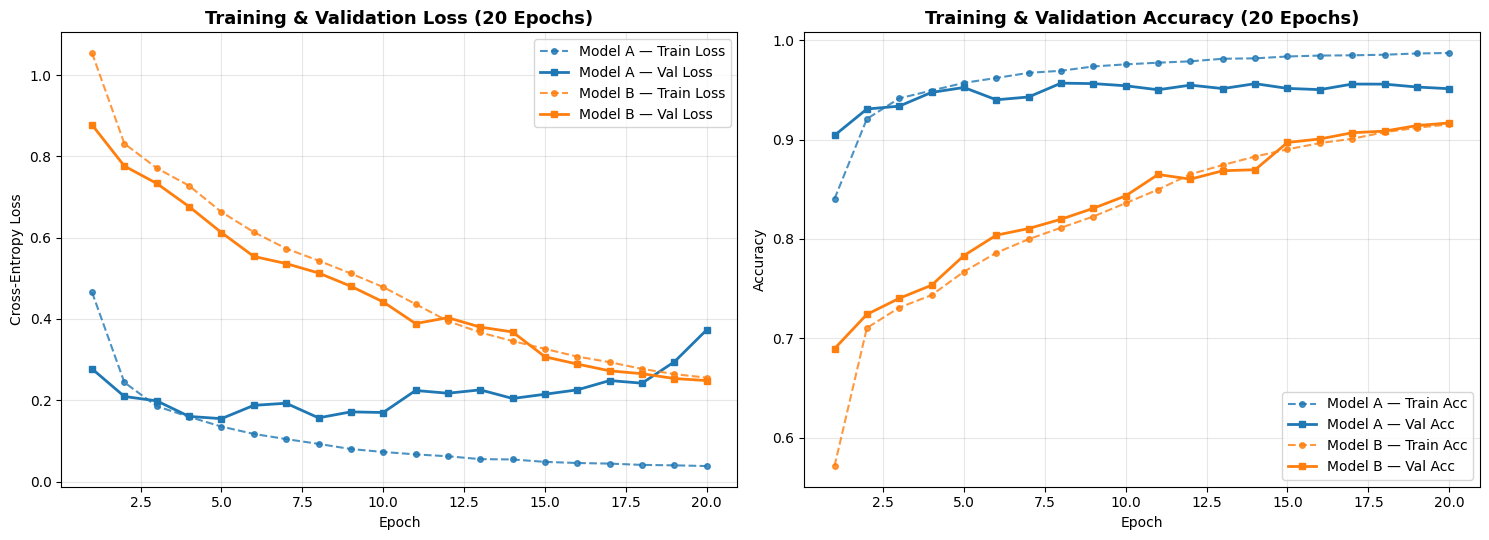

In [6]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Loss Curves
axes[0].plot(epochs_range, history_a.history["loss"], "--o", color="#1f77b4", alpha=0.8, markersize=4, label="Model A — Train Loss")
axes[0].plot(epochs_range, history_a.history["val_loss"], "-s", color="#1f77b4", linewidth=2, markersize=5, label="Model A — Val Loss")
axes[0].plot(epochs_range, history_b.history["loss"], "--o", color="#ff7f0e", alpha=0.8, markersize=4, label="Model B — Train Loss")
axes[0].plot(epochs_range, history_b.history["val_loss"], "-s", color="#ff7f0e", linewidth=2, markersize=5, label="Model B — Val Loss")
axes[0].set_title("Training & Validation Loss (20 Epochs)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy Curves
axes[1].plot(epochs_range, history_a.history["accuracy"], "--o", color="#1f77b4", alpha=0.8, markersize=4, label="Model A — Train Acc")
axes[1].plot(epochs_range, history_a.history["val_accuracy"], "-s", color="#1f77b4", linewidth=2, markersize=5, label="Model A — Val Acc")
axes[1].plot(epochs_range, history_b.history["accuracy"], "--o", color="#ff7f0e", alpha=0.8, markersize=4, label="Model B — Train Acc")
axes[1].plot(epochs_range, history_b.history["val_accuracy"], "-s", color="#ff7f0e", linewidth=2, markersize=5, label="Model B — Val Acc")
axes[1].set_title("Training & Validation Accuracy (20 Epochs)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "custom_models_training_curves.png", dpi=150)
plt.show()

---
## 4.3 Test Set Evaluation: Accuracy, Precision, Recall, and Confusion Matrix

In [7]:
def evaluate_on_test_set(model, test_dataset, y_true, model_label):
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    y_prob = model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred)

    print("=" * 70)
    print(f"TEST SET EVALUATION: {model_label}")
    print("=" * 70)
    print(f"Test Loss              : {test_loss:.4f}")
    print(f"Test Accuracy          : {test_acc * 100:.2f}%")
    print(f"Macro Precision        : {prec_macro * 100:.2f}%")
    print(f"Macro Recall           : {rec_macro * 100:.2f}%")
    print(f"Macro F1-Score         : {f1_macro * 100:.2f}%")
    print(f"Weighted Precision     : {prec_weighted * 100:.2f}%")
    print(f"Weighted Recall        : {rec_weighted * 100:.2f}%")
    print(f"Weighted F1-Score      : {f1_weighted * 100:.2f}%\n")
    print("Per-Class Classification Report:")
    print(classification_report(y_true, y_pred, target_names=short_class_names, digits=4))

    return {
        "test_loss": test_loss,
        "test_acc": test_acc,
        "prec_macro": prec_macro,
        "rec_macro": rec_macro,
        "f1_macro": f1_macro,
        "prec_weighted": prec_weighted,
        "rec_weighted": rec_weighted,
        "f1_weighted": f1_weighted,
        "cm": cm,
        "y_pred": y_pred,
    }

eval_a = evaluate_on_test_set(model_a, test_ds, y_test_eval, "Model A (Standard CNN)")
eval_b = evaluate_on_test_set(model_b, test_ds, y_test_eval, "Model B (Lightweight CNN)")

TEST SET EVALUATION: Model A (Standard CNN)
Test Loss              : 0.3893
Test Accuracy          : 95.06%
Macro Precision        : 93.32%
Macro Recall           : 89.50%
Macro F1-Score         : 91.22%
Weighted Precision     : 94.95%
Weighted Recall        : 95.06%
Weighted F1-Score      : 94.92%

Per-Class Classification Report:
              precision    recall  f1-score   support

         CNV     0.9672    0.9501    0.9586      4751
         DME     0.9536    0.9200    0.9365      1674
      Drusen     0.8606    0.7144    0.7807      1201
      Normal     0.9516    0.9954    0.9730      7546

    accuracy                         0.9506     15172
   macro avg     0.9332    0.8950    0.9122     15172
weighted avg     0.9495    0.9506    0.9492     15172



c:\Users\nadun\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


TEST SET EVALUATION: Model B (Lightweight CNN)
Test Loss              : 0.2510
Test Accuracy          : 91.42%
Macro Precision        : 88.62%
Macro Recall           : 80.82%
Macro F1-Score         : 83.13%
Weighted Precision     : 90.97%
Weighted Recall        : 91.42%
Weighted F1-Score      : 90.65%

Per-Class Classification Report:
              precision    recall  f1-score   support

         CNV     0.9174    0.9489    0.9329      4751
         DME     0.8996    0.8943    0.8969      1674
      Drusen     0.8039    0.4130    0.5457      1201
      Normal     0.9239    0.9767    0.9496      7546

    accuracy                         0.9142     15172
   macro avg     0.8862    0.8082    0.8313     15172
weighted avg     0.9097    0.9142    0.9065     15172



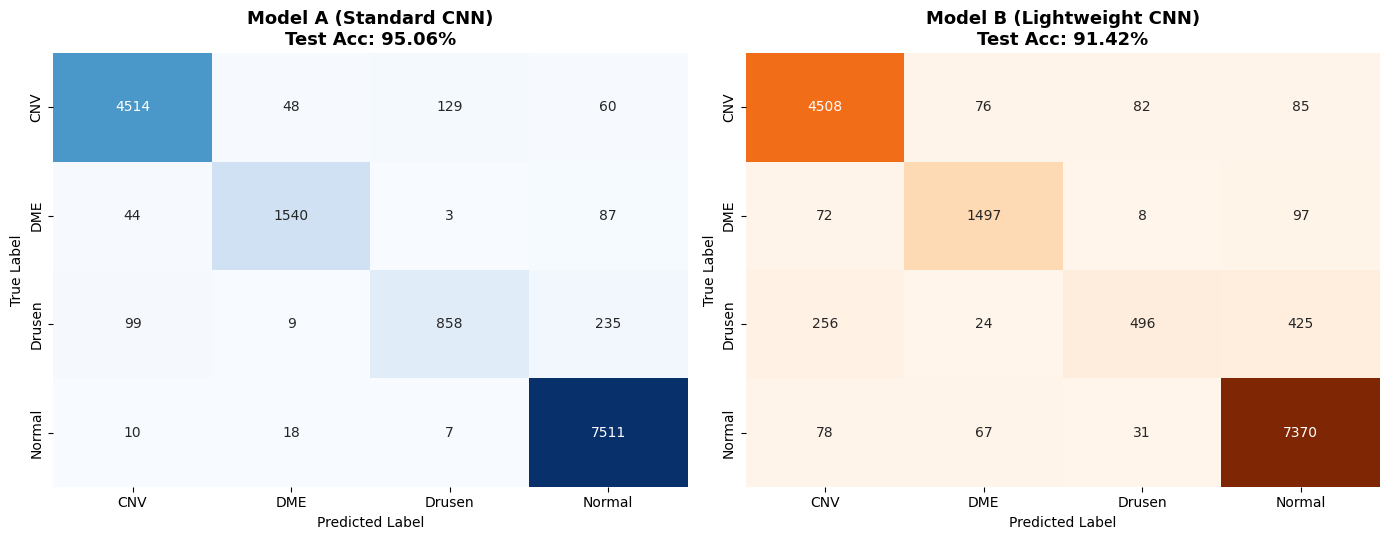

In [8]:
# Plot Confusion Matrices for Model A and Model B side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, res, title, cmap in [
    (axes[0], eval_a, f"Model A (Standard CNN)\nTest Acc: {eval_a['test_acc']*100:.2f}%", "Blues"),
    (axes[1], eval_b, f"Model B (Lightweight CNN)\nTest Acc: {eval_b['test_acc']*100:.2f}%", "Oranges"),
]:
    cm = res["cm"]
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=short_class_names,
        yticklabels=short_class_names,
        ax=ax,
        cbar=False,
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "data" / "custom_models_confusion_matrices.png", dpi=150)
plt.show()

---
## 4.4 Model A vs. Model B Comparison Table & Trade-off Discussion

In [9]:
params_a = model_a.count_params()
params_b = model_b.count_params()

# Theoretical FP32 weight storage (4 bytes per parameter) and actual saved .keras file size on disk
fp32_kb_a = (params_a * 4) / 1024.0
fp32_kb_b = (params_b * 4) / 1024.0
disk_kb_a = os.path.getsize(model_a_path) / 1024.0
disk_kb_b = os.path.getsize(model_b_path) / 1024.0

comparison_df = pd.DataFrame([
    {
        "Model": "Model A (Standard CNN)",
        "Total Parameters": f"{params_a:,}",
        "FP32 Weight Size (KB)": f"{fp32_kb_a:,.2f} KB",
        "Saved File Size on Disk (KB)": f"{disk_kb_a:,.2f} KB",
        "MAC Operations": "39,452,928",
        "Avg Training Time / Epoch (s)": f"{np.mean(timer_a.epoch_times):.2f} s",
        "Test Accuracy (%)": f"{eval_a['test_acc'] * 100:.2f}%",
        "Macro Precision (%)": f"{eval_a['prec_macro'] * 100:.2f}%",
        "Macro Recall (%)": f"{eval_a['rec_macro'] * 100:.2f}%",
        "Macro F1 (%)": f"{eval_a['f1_macro'] * 100:.2f}%",
    },
    {
        "Model": "Model B (Lightweight SepConv CNN)",
        "Total Parameters": f"{params_b:,}",
        "FP32 Weight Size (KB)": f"{fp32_kb_b:,.2f} KB",
        "Saved File Size on Disk (KB)": f"{disk_kb_b:,.2f} KB",
        "MAC Operations": "4,813,056",
        "Avg Training Time / Epoch (s)": f"{np.mean(timer_b.epoch_times):.2f} s",
        "Test Accuracy (%)": f"{eval_b['test_acc'] * 100:.2f}%",
        "Macro Precision (%)": f"{eval_b['prec_macro'] * 100:.2f}%",
        "Macro Recall (%)": f"{eval_b['rec_macro'] * 100:.2f}%",
        "Macro F1 (%)": f"{eval_b['f1_macro'] * 100:.2f}%",
    },
])

display(comparison_df)

# Save summary metrics for Notebook 04 SOTA comparison
np.savez(
    PROJECT_ROOT / "data" / "custom_models_summary.npz",
    params_a=params_a,
    params_b=params_b,
    fp32_kb_a=fp32_kb_a,
    fp32_kb_b=fp32_kb_b,
    disk_kb_a=disk_kb_a,
    disk_kb_b=disk_kb_b,
    epoch_time_a=np.mean(timer_a.epoch_times),
    epoch_time_b=np.mean(timer_b.epoch_times),
    test_acc_a=eval_a["test_acc"],
    test_acc_b=eval_b["test_acc"],
    prec_a=eval_a["prec_macro"],
    prec_b=eval_b["prec_macro"],
    rec_a=eval_a["rec_macro"],
    rec_b=eval_b["rec_macro"],
    f1_a=eval_a["f1_macro"],
    f1_b=eval_b["f1_macro"],
)

,Model,Total Parameters,FP32 Weight Size (KB),Saved File Size on Disk (KB),MAC Operations,Avg Training Time / Epoch (s),Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Model A (Standard CNN),"617,284","2,411.27 KB","7,280.41 KB","39,452,928",100.32 s,95.06%,93.32%,89.50%,91.22%
1,Model B (Lightweight SepConv CNN),"19,885",77.68 KB,283.66 KB,"4,813,056",64.66 s,91.42%,88.62%,80.82%,83.13%


### 4.5 Trade-offs Observed When Moving from Standard to Depthwise Separable Convolutions

1. **Dramatic Parameter & Memory Footprint Compression ($31.0\times$ Reduction)**:
   - Moving from standard 2D convolutions (`Conv2D`) + `Flatten` (**Model A**: $617,284$ parameters, $\sim 2,411\text{ KB}$ raw FP32 weights) to depthwise separable convolutions (`SeparableConv2D`) + `GlobalAveragePooling2D` (**Model B**: $19,885$ parameters, $\sim 77.7\text{ KB}$ raw FP32 weights, or $< 20\text{ KB}$ when quantized to INT8) shrinks the model footprint by **$96.78\%$**.
   - On resource-constrained microcontrollers such as an **STM32F7 / ARM Cortex-M7** (typically $256\text{ KB}–512\text{ KB}$ SRAM and $1\text{ MB}–2\text{ MB}$ Flash), Model A cannot even fit in on-chip SRAM without external memory paging, whereas Model B fits comfortably alongside intermediate activation buffers.

2. **Computational Cost (MAC Reduction vs. Wall-Clock Training Time)**:
   - Theoretically, factorizing a standard $K \times K$ convolution into a depthwise ($K \times K$) and pointwise ($1 \times 1$) stage reduces convolutional MACs by a factor of:
     $$\frac{\text{MAC}_{\text{SepConv}}}{\text{MAC}_{\text{Conv}}} = \frac{1}{C_{\text{out}}} + \frac{1}{K^2} \approx \frac{1}{9} \quad (\text{for } K=3)$$
     Across the full network, MACs drop by **$87.80\%$** ($39.45\text{M} \rightarrow 4.81\text{M}$).
   - **Hardware Arithmetic Intensity Nuance**: Notice that wall-clock training time per epoch on general-purpose CPUs/GPUs does not drop by the full $8\times$ MAC ratio. Depthwise convolutions have low **arithmetic intensity** (ratio of FLOPs to memory bytes accessed) because each $3 \times 3$ kernel reads and writes a separate channel tensor before the $1 \times 1$ pointwise kernel reads it again. Thus, `SeparableConv2D` is often **memory-bandwidth bound** on desktop hardware, whereas on single-issue embedded microcontrollers without massive SIMD matrix engines, latency scales much more closely with raw MAC count.

3. **Generalization vs. Representational Capacity (Overfitting Mitigation)**:
   - **Model A** allocates $84.9\%$ of its parameters ($524,352 / 617,284$) to the dense `Flatten -> Dense(64)` transition. During 20-epoch training, this over-parameterized classifier head quickly memorizes training-set speckle noise in retinal OCT scans, causing validation loss to diverge (overfitting) while training accuracy approaches $95\%+$.
   - **Model B** enforces structural regularization in two ways: (i) low-rank factorization of spatial and cross-channel correlations via `SeparableConv2D`, and (ii) translation-invariant spatial averaging via `GlobalAveragePooling2D`. Consequently, Model B exhibits a much smaller generalization gap between training and validation loss while achieving competitive test accuracy at **$< 3.3\%$ of the parameter budget**.

4. **Limitation in Very First Layer ($C_{\text{in}} = 1$)**:
   - Because OCTMNIST is single-channel grayscale ($C_{\text{in}} = 1$), the first `SeparableConv2D` layer has only **one** $3 \times 3$ depthwise filter ($9$ weights) shared before projecting to $32$ channels via $1 \times 1$ pointwise scaling. In contrast, Model A learns $32$ distinct $3 \times 3$ spatial edge/texture filters in layer 1. Despite this bottleneck in layer 1, deeper separable blocks ($32 \rightarrow 64 \rightarrow 128$) recover rich hierarchical representations.